In [2]:
import pandas as pd

# Load dataset
df = pd.read_csv("../dataset/churn_data.csv")
# Show first 5 rows
df.head()

,CustomerID,Age,Gender,Tenure,MonthlyCharges,Contract,PaymentMethod,TotalCharges,Churn
0,1,56,Female,68,147.58,Two year,Bank transfer,10052.03,No
1,2,69,Male,32,22.54,Month-to-month,Mailed check,686.78,No
2,3,46,Female,10,52.47,One year,Electronic check,537.88,No
3,4,32,Male,22,109.67,Month-to-month,Mailed check,2390.04,Yes
4,5,60,Female,54,130.98,Month-to-month,Credit card,7081.28,No


In [3]:
df.info()
print(df.describe())
print(df.columns)

<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 9 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   CustomerID      100000 non-null  int64  
 1   Age             100000 non-null  int64  
 2   Gender          100000 non-null  str    
 3   Tenure          100000 non-null  int64  
 4   MonthlyCharges  100000 non-null  float64
 5   Contract        100000 non-null  str    
 6   PaymentMethod   100000 non-null  str    
 7   TotalCharges    100000 non-null  float64
 8   Churn           100000 non-null  str    
dtypes: float64(2), int64(3), str(4)
memory usage: 9.9 MB
          CustomerID            Age         Tenure  MonthlyCharges  \
count  100000.000000  100000.000000  100000.000000   100000.000000   
mean    50000.500000      49.027240      36.527090       79.974933   
std     28867.657797      18.177862      20.789552       40.491961   
min         1.000000      18.000000       1.000000       1

In [4]:
df.isnull().sum()

CustomerID        0
Age               0
Gender            0
Tenure            0
MonthlyCharges    0
Contract          0
PaymentMethod     0
TotalCharges      0
Churn             0
dtype: int64

In [5]:
df.ffill(inplace=True)

,CustomerID,Age,Gender,Tenure,MonthlyCharges,Contract,PaymentMethod,TotalCharges,Churn
0,1,56,Female,68,147.58,Two year,Bank transfer,10052.03,No
1,2,69,Male,32,22.54,Month-to-month,Mailed check,686.78,No
2,3,46,Female,10,52.47,One year,Electronic check,537.88,No
3,4,32,Male,22,109.67,Month-to-month,Mailed check,2390.04,Yes
4,5,60,Female,54,130.98,Month-to-month,Credit card,7081.28,No
...,...,...,...,...,...,...,...,...,...
99995,99996,31,Male,49,26.07,Month-to-month,Electronic check,1220.50,No
99996,99997,64,Female,44,123.22,Month-to-month,Mailed check,5384.38,No
99997,99998,48,Other,32,75.37,Month-to-month,Credit card,2372.33,Yes
99998,99999,42,Female,60,114.00,Month-to-month,Mailed check,6826.55,No


In [6]:
df.duplicated().sum()
df.drop_duplicates(inplace=True)

In [7]:
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')

In [8]:
df['Churn'].value_counts()

Churn
No     66856
Yes    33144
Name: count, dtype: int64

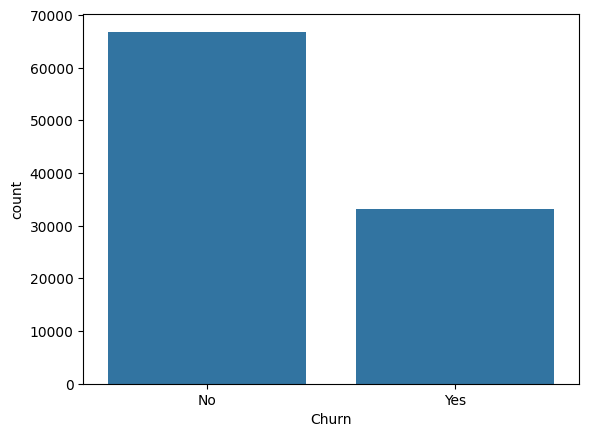

In [9]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.countplot(x='Churn', data=df)
plt.show()

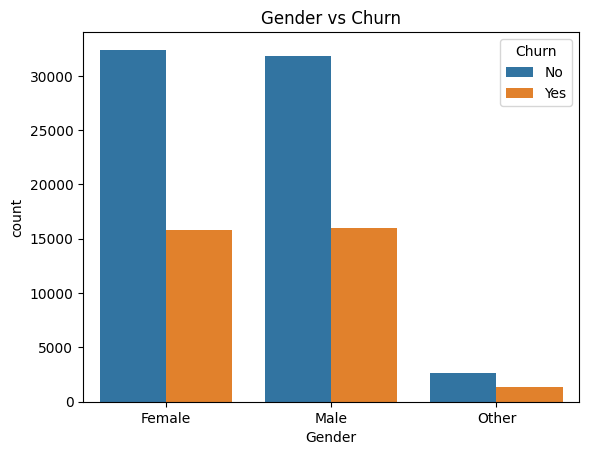

In [10]:
sns.countplot(x='Gender', hue='Churn', data=df)
plt.title("Gender vs Churn")
plt.show()

Churn distribution across genders appears relatively balanced, indicating that gender is not a strong factor influencing customer churn.

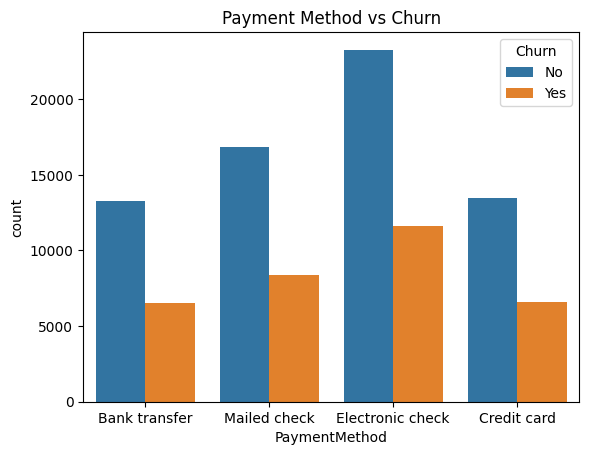

In [11]:
sns.countplot(x='PaymentMethod', hue='Churn', data=df)
plt.title("Payment Method vs Churn")
plt.show()

Certain payment methods such as electronic check show higher churn rates, indicating potential dissatisfaction in billing or payment experience.

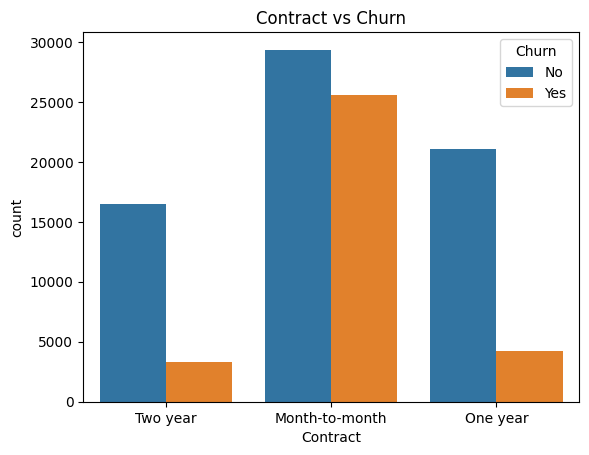

In [12]:
sns.countplot(x='Contract', hue='Churn', data=df)
plt.title("Contract vs Churn")
plt.show()

Customers with month-to-month contracts exhibit significantly higher churn rates compared to long-term contract customers, suggesting lack of commitment increases churn risk.

In [13]:
pd.crosstab(df['Contract'], df['Churn'], normalize='index') * 100

Churn,No,Yes
Contract,,
Month-to-month,53.442593,46.557407
One year,83.250861,16.749139
Two year,83.121469,16.878531


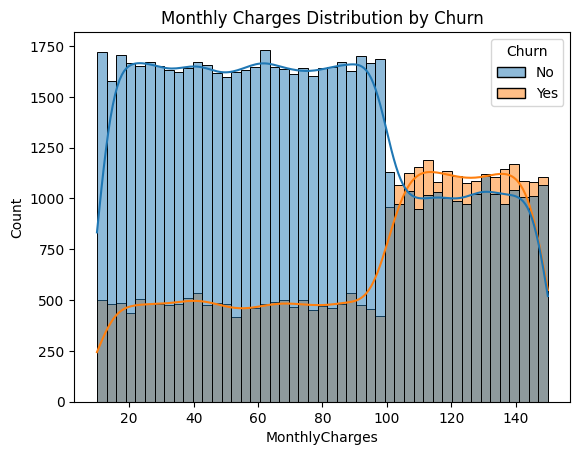

In [ ]:
sns.histplot(data=df, x='MonthlyCharges', hue='Churn', kde=True)
plt.title("Monthly Charges Distribution by Churn")
plt.show()

Modelling

x = features/independent variables
use all remianing fetures to predict churn
we remove customerID bcz i doesnt have any impact on churn
and we remove churn bcz thats the answer itself so thats why,
axis=1 means remove columns
y = output/dependent variables
means i want to predict churn thats why y = df[churn]

In [15]:
X = df.drop(['CustomerID','Churn'], axis=1)
y = df['Churn']

converting categorical values into numbers bcz model doesnt understand text so here .map function is used to replace values using dictionary.

In [16]:
y = y.map({'Yes':1, 'No':0})

get_dummies = used to convert categorical values into numerical format so ml models can understand and process them 
drop_first=true = used to remove one column to avoid confusion or multicollinearity

In [17]:
X = pd.get_dummies(X, drop_first=True)

I split the dataset into training and testing sets to evaluate model performance on unseen data and avoid overfitting.
training data = used to teach the model
testing data = used to check performance
x = features
y = output
test_size = 0.2 (20% test data)
random_state = 42(it fixes randomness, so every time u run -> same split)

In [18]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [19]:
df.isnull().sum()

CustomerID        0
Age               0
Gender            0
Tenure            0
MonthlyCharges    0
Contract          0
PaymentMethod     0
TotalCharges      0
Churn             0
dtype: int64

errors = coerce
it handles bad/invalid values means ,invalid values becomes NaN instead of crashing.

In [20]:
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')

In [21]:
df = df.dropna()

In [22]:
df['TotalCharges'].fillna(df['TotalCharges'].median(), inplace=True)

C:\Users\keert\AppData\Local\Temp\ipykernel_15040\2840544469.py:1: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through chained assignment using an inplace method.
Such inplace method never works to update the original DataFrame or Series, because the intermediate object on which we are setting values always behaves as a copy (due to Copy-on-Write).

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' instead, to perform the operation inplace on the original object, or try to avoid an inplace operation using 'df[col] = df[col].method(value)'.

See the documentation for a more detailed explanation: https://pandas.pydata.org/pandas-docs/stable/user_guide/copy_on_write.html
  df['TotalCharges'].fillna(df['TotalCharges'].median(), inplace=True)


0        10052.03
1          686.78
2          537.88
3         2390.04
4         7081.28
           ...   
99995     1220.50
99996     5384.38
99997     2372.33
99998     6826.55
99999     3828.60
Name: TotalCharges, Length: 100000, dtype: float64

this is called feature scaling(standardization)
why use this -> bcz ml models get biased toward bigger numbers, after scaling all features become comparable
ex  student a = marks = 100
    student b = 1000
    direct comare b is high 
    if convert to percentage that becomes fair comparison
so scaling shifts values around 0 and scale them based on spread
fit() -> learns mean of each column and std
transform() -> applies scaling (lerans only from training data)
for test data we use only .transform bcz u must not learn from test data.

In [23]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

importing logistic regression algorithm(classification algorithm ,used to predict binary outcomes like churn(yes/no))
creating model object
max_iter = 2000 (max no of iterations,increased so model can learn properly)
trained the model, and learns relationship between features and churn
Since churn prediction is a binary classification problem, Logistic Regression was a good baseline model due to its interpretability.”

I used class_weight='balanced' to handle bias toward majority class and improve churn prediction accuracy.

In [32]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(max_iter=2000, class_weight='balanced')
model.fit(X_train, y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add a L2 penalty term and it is the default choice;- `'l1'`: add a L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'` and `l1_ratio` set to any float between 0 and 1 for `'penalty='elasticnet'`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation `) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",'balanced'
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary ` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :ter

In [42]:
pip install joblib

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.3 -> 26.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [49]:
import pickle
import os

os.makedirs("../model", exist_ok=True)

with open("../model/churn_model.pkl", "wb") as file:
    pickle.dump(model, file)

model is predicting using test or unseen data(prediction in binary like 0 , 1)
accuracy = checks overall correctness
     = correct predictions / total predictions
classification report = it gives 
 1.precision = how many predicted churn are actually churn
 2.recall = how many actual churn we correctly found
 3.f1score = balance of precision + recall

The model achieves around 72% accuracy and performs well in identifying non-churn customers. However, the recall for churn customers is relatively low at 46%, meaning the model fails to capture a significant portion of customers who are likely to leave. This is reflected in the high number of false negatives (3597), which is a critical business concern.

In [34]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
y_prob = model.predict_proba(X_test)[:,1]
y_pred_new = (y_prob > 0.3).astype(int)

print("Accuracy:", accuracy_score(y_test, y_pred))
print("\nClassification Report:\n", classification_report(y_test, y_pred))
print("\nConfusion Matrix:\n",confusion_matrix(y_test, y_pred))

Accuracy: 0.72375

Classification Report:
               precision    recall  f1-score   support

           0       0.76      0.85      0.80     13294
           1       0.62      0.46      0.53      6706

    accuracy                           0.72     20000
   macro avg       0.69      0.66      0.67     20000
weighted avg       0.71      0.72      0.71     20000


Confusion Matrix:
 [[11366  1928]
 [ 3597  3109]]


visualize model performance using a confusion matrix heatmap
output is like = [[truenegative(TN)    Falsepositive(FP)]
                  [Falsenegative(FN)   Truepositive(TP)]]
annot = true (shows numbers inside boxes)
fmt = 'd'(display as integers)
“I used a confusion matrix to evaluate classification performance.
It helped me identify that the model was missing churn customers (false negatives), which is critical because those are the customers we want to retain.”

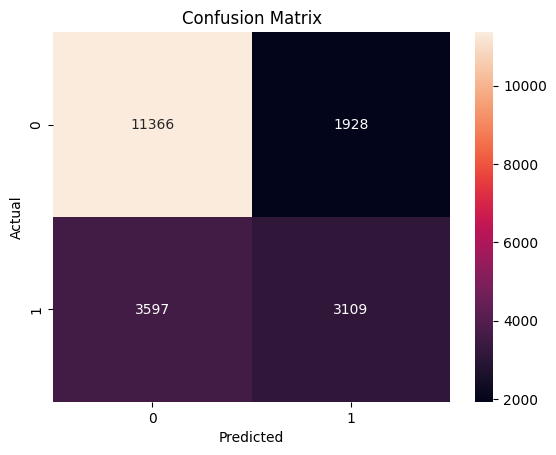

In [32]:
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred)

sns.heatmap(cm, annot=True, fmt='d')
plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

after training, it learns weights(coefficients) for each feature
model.coef_[0] = array of importance values for all features
index=x.columns 
     this links each coeff to its feature name
pd.series
     converts coeff into a readable format
sort_values
     sort features by importancce(highest first)

In [38]:
import pandas as pd

importance = pd.Series(model.coef_[0], index=X.columns)
importance.sort_values(ascending=False).head(10)


MonthlyCharges                    0.508046
TotalCharges                      0.290970
Gender_Male                       0.018852
PaymentMethod_Mailed check        0.018326
Gender_Other                      0.012423
PaymentMethod_Electronic check    0.005041
PaymentMethod_Credit card         0.002314
Age                              -0.001708
Contract_Two year                -0.682402
Tenure                           -0.721871
dtype: float64

<Axes: >

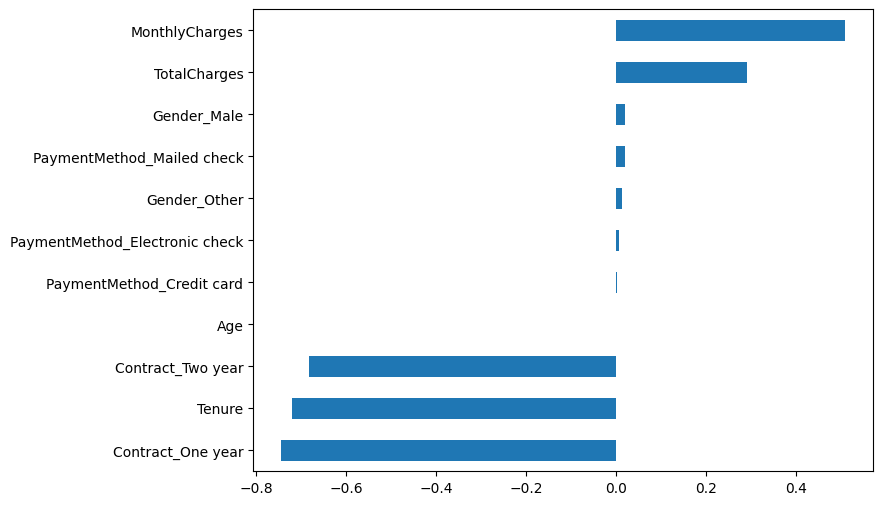

In [39]:
importance.sort_values().plot(kind='barh', figsize=(8,6))

💼 BUSINESS INSIGHTS
Month-to-month contracts → highest churn
High monthly charges → increase churn
Low tenure → customers leave early


💡 RECOMMENDATIONS
Offer long-term discounts
Improve onboarding experience
Provide pricing benefits